Dataset Preview:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset Shape: (150, 5)

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600

/tmp/ipykernel_52772/2756953678.py:26: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


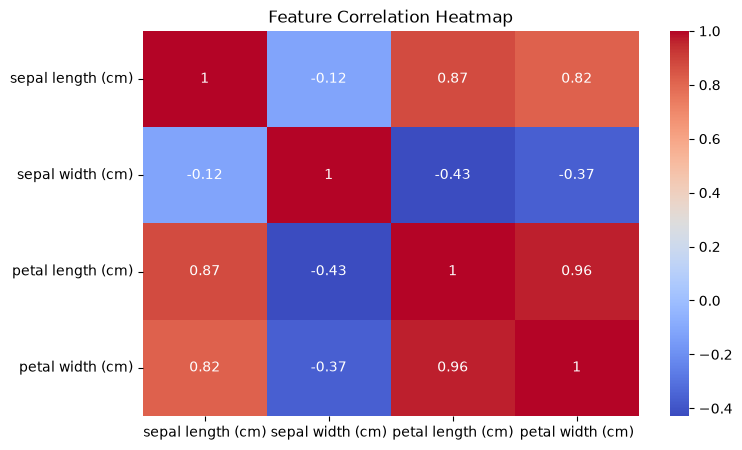


Cluster Distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


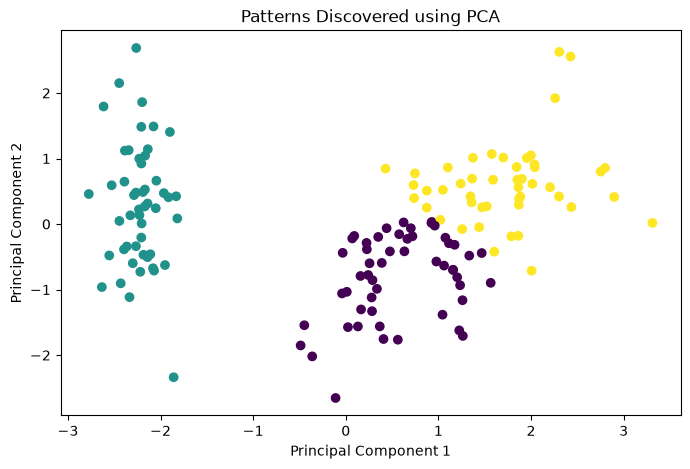


Classification Accuracy: 0.9

Important Features:
petal width (cm)     0.437185
petal length (cm)    0.431466
sepal length (cm)    0.116349
sepal width (cm)     0.015000
dtype: float64


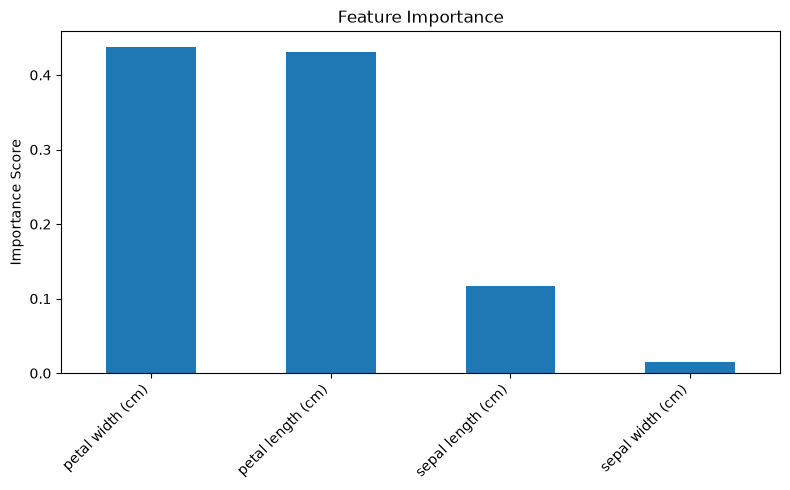


Average Measurements by Species:
         sepal length (cm)  sepal width (cm)  petal length (cm)  \
Species                                                           
0                    5.006             3.428              1.462   
1                    5.936             2.770              4.260   
2                    6.588             2.974              5.552   

         petal width (cm)  
Species                    
0                   0.246  
1                   1.326  
2                   2.026  

Knowledge Discovery Completed Successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load Dataset
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Species'] = iris.target

print("Dataset Preview:")
print(df.head())

print("\nDataset Shape:", df.shape)

# 2. Data Preprocessing
df.dropna(inplace=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(
    df.drop('Species', axis=1)
)

# 3. Exploratory Data Analysis
print("\nStatistical Summary:")
print(df.describe())

plt.figure(figsize=(8, 5))
sns.heatmap(
    df.drop('Species', axis=1).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Feature Correlation Heatmap")
plt.show()

# 4. Knowledge Discovery using K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nCluster Distribution:")
print(df['Cluster'].value_counts())

# 5. Pattern Discovery using PCA
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    reduced_data[:, 0],
    reduced_data[:, 1],
    c=df['Cluster'],
    cmap='viridis'
)
plt.title("Patterns Discovered using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# 6. Classification using Random Forest
X = df.drop(['Species', 'Cluster'], axis=1)
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("\nClassification Accuracy:",
      accuracy_score(y_test, predictions))

# 7. Discover Important Features
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nImportant Features:")
print(importance)

plt.figure(figsize=(8, 5))
importance.plot(kind='bar')
plt.title("Feature Importance")
plt.ylabel("Importance Score")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 8. Discover Trends using Group Analysis
print("\nAverage Measurements by Species:")
print(df.groupby('Species')[iris.feature_names].mean())

print("\nKnowledge Discovery Completed Successfully!")